In [1]:
import os
import torch
import torch.nn as nn
from torchvision import models

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

BASE_PATH = "/content/drive/MyDrive/UncertaintyAI"
DATA_PATH = os.path.join(BASE_PATH, "cifar100")
MODEL_PATH = os.path.join(BASE_PATH, "resnet18_cifar100.pth")

os.makedirs(BASE_PATH, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])


full_train = datasets.CIFAR100(
    root=DATA_PATH,
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR100(
    root=DATA_PATH,
    train=False,
    download=True,
    transform=transform
)


train_dataset, val_dataset = random_split(
    full_train,
    [40000, 10000],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset, batch_size=128,
    shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=256,
    shuffle=False, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=256,
    shuffle=False, num_workers=2
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))
print("Classes:", len(full_train.classes))

Mounted at /content/drive
Device: cuda
GPU: Tesla T4
Training images: 40000
Validation images: 10000
Testing images: 10000
Classes: 100


In [3]:
import torch
import torch.nn as nn
from torchvision import models

model = models.resnet18(
    weights=None if os.path.exists(MODEL_PATH)
    else models.ResNet18_Weights.DEFAULT
)

model.fc = nn.Sequential(
    nn.Dropout(p=0.2),
    nn.Linear(model.fc.in_features, 100)
)

model = model.to(device)

if os.path.exists(MODEL_PATH):

    checkpoint = torch.load(
        MODEL_PATH,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(checkpoint)
    print("Saved model loaded. Training skipped!")

else:

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.0003
    )

    epochs = 3

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            total += labels.size(0)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Loss: {total_loss / len(train_loader):.4f} | "
            f"Accuracy: {100 * correct / total:.2f}%"
        )

    torch.save(model.state_dict(), MODEL_PATH)
    print("Training complete! Model saved to Google Drive.")

model.eval()

Saved model loaded. Training skipped!


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [4]:
import torch
import torch.nn.functional as F

model.eval()
model.fc[0].train()

mc_passes = 5
all_probs = []
all_labels = []

max_eval_batches = 10

with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(test_loader):

        if batch_idx >= max_eval_batches:
            break

        images = images.to(device)

        repeated_probs = []

        for _ in range(mc_passes):
            outputs = model(images)
            probs = F.softmax(outputs, dim=1)
            repeated_probs.append(probs)

        repeated_probs = torch.stack(repeated_probs)
        mean_probs = repeated_probs.mean(dim=0)

        all_probs.append(mean_probs.cpu())
        all_labels.append(labels.cpu())

model.eval()

probs = torch.cat(all_probs)
labels = torch.cat(all_labels)

predictions = probs.argmax(dim=1)
confidence = probs.max(dim=1).values

accuracy = (predictions == labels).float().mean().item()

entropy = -(
    probs * probs.clamp_min(1e-12).log()
).sum(dim=1)

one_hot = F.one_hot(
    labels,
    num_classes=100
).float()

brier_score = (
    (probs - one_hot) ** 2
).sum(dim=1).mean().item()


def calculate_ece(probs, labels, bins=15):
    confidence = probs.max(dim=1).values
    predictions = probs.argmax(dim=1)
    correct = (predictions == labels).float()

    ece = 0.0

    for i in range(bins):
        lower = i / bins
        upper = (i + 1) / bins

        if i == 0:
            mask = (
                (confidence >= lower) &
                (confidence <= upper)
            )
        else:
            mask = (
                (confidence > lower) &
                (confidence <= upper)
            )

        if mask.any():
            bin_accuracy = correct[mask].mean()
            bin_confidence = confidence[mask].mean()
            bin_weight = mask.float().mean()

            ece += (
                bin_weight *
                abs(bin_accuracy - bin_confidence)
            ).item()

    return ece


ece = calculate_ece(probs, labels)

print("\n===== UNCERTAINTYAI RESULTS =====")
print("Evaluation images:", len(labels))
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Brier score: {brier_score:.4f}")
print(f"Expected Calibration Error: {ece:.4f}")
print(f"Average entropy: {entropy.mean().item():.4f}")
print(f"Average confidence: {confidence.mean().item() * 100:.2f}%")


===== UNCERTAINTYAI RESULTS =====
Evaluation images: 2560
Accuracy: 69.45%
Brier score: 0.4200
Expected Calibration Error: 0.0844
Average entropy: 0.7650
Average confidence: 77.85%


In [6]:

from google.colab import files
from PIL import Image
import torch
import torch.nn.functional as F

uploaded = files.upload()
image_path = next(iter(uploaded))

image = Image.open(image_path).convert("RGB")
image_tensor = transform(image).unsqueeze(0).to(device)

model.eval()
model.fc[0].train()

mc_passes = 30
repeated_probs = []

with torch.no_grad():
    for _ in range(mc_passes):
        outputs = model(image_tensor)
        probabilities = F.softmax(outputs, dim=1)
        repeated_probs.append(probabilities)

repeated_probs = torch.stack(repeated_probs)

mean_probs = repeated_probs.mean(dim=0)[0]

predicted_index = mean_probs.argmax().item()
confidence = mean_probs.max().item()

entropy = -(
    mean_probs * mean_probs.clamp_min(1e-12).log()
).sum().item()

prediction_variance = (
    repeated_probs.var(dim=0).mean().item()
)

predicted_class = full_train.classes[predicted_index]


CONFIDENCE_THRESHOLD = 0.60

print("\n===== UNCERTAINTYAI RESULTS =====")
print("Uploaded image:", image_path)
print("Predicted class:", predicted_class)
print(f"Confidence: {confidence * 100:.2f}%")
print(f"Predictive entropy: {entropy:.4f}")
print(f"Prediction variance: {prediction_variance:.6f}")

if confidence < CONFIDENCE_THRESHOLD:
    print("\nDECISION: HUMAN REVIEW REQUIRED")
    print("Reason: Confidence is below the demo threshold.")
else:
    print("\nDECISION: TENTATIVE PREDICTION")
    print("Note: Confidence alone does not guarantee correctness.")

model.eval()


Saving Amur-Tiger-©Nina-Day-600x380.jpg to Amur-Tiger-©Nina-Day-600x380.jpg

===== UNCERTAINTYAI RESULTS =====
Uploaded image: Amur-Tiger-©Nina-Day-600x380.jpg
Predicted class: ray
Confidence: 29.37%
Predictive entropy: 3.0966
Prediction variance: 0.000137

DECISION: HUMAN REVIEW REQUIRED
Reason: Confidence is below the demo threshold.


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [7]:

import torch
import torch.nn.functional as F

device = next(model.parameters()).device
model.eval()

all_probs = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        probs = F.softmax(outputs, dim=1)

        all_probs.append(probs.cpu())
        all_labels.append(labels.cpu())


probs = torch.cat(all_probs)
labels = torch.cat(all_labels)

confidence, predictions = probs.max(dim=1)
correct_mask = predictions == labels

test_accuracy = correct_mask.float().mean().item() * 100

print("Evaluation completed!")
print("Number of test images:", len(labels))
print(f"Baseline test accuracy: {test_accuracy:.2f}%")
print("Prediction probabilities shape:", tuple(probs.shape))
print("Labels shape:", tuple(labels.shape))


Evaluation completed!
Number of test images: 10000
Baseline test accuracy: 69.11%
Prediction probabilities shape: (10000, 100)
Labels shape: (10000,)


Running Monte Carlo Dropout on validation data...
Running Monte Carlo Dropout on test data...


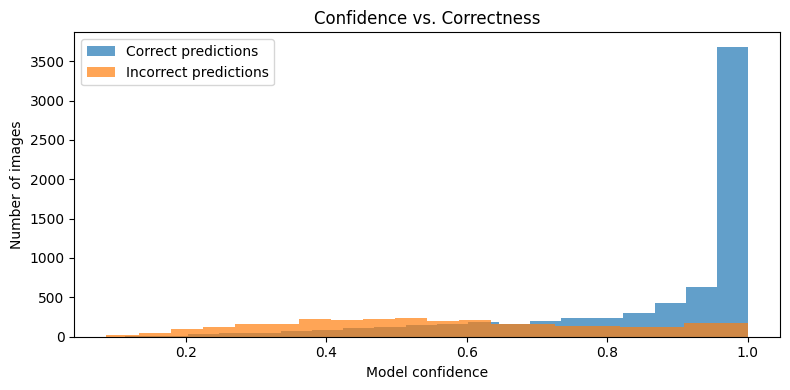

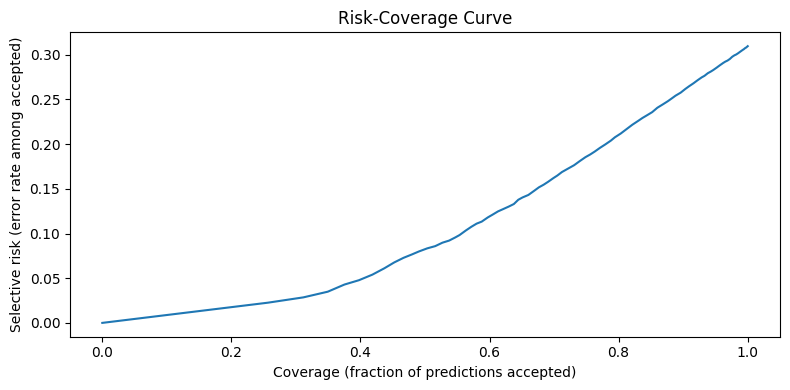

,Metric,Result
0,Baseline accuracy (normal model),69.11%
1,MC Dropout accuracy,69.04%
2,Brier score,0.4283
3,Expected Calibration Error (ECE),0.0863
4,Mean confidence on correct predictions,86.67%
5,Mean confidence on incorrect predictions,57.51%
6,Validation-selected threshold,70%
7,Test coverage,66.02%
8,Test selective risk,14.31%
9,Mean predictive entropy,0.7757


In [8]:

import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML


device = next(model.parameters()).device
model.eval()

if not isinstance(model.fc[0], torch.nn.Dropout):
    raise ValueError("Expected a Dropout layer at model.fc[0]. Check your model architecture.")

def mc_predict(loader, passes=10):
    probability_runs = []
    saved_labels = None

    for run in range(passes):
        batch_probs = []
        batch_labels = []

        model.eval()
        model.fc[0].train()

        with torch.no_grad():
            for images, targets in loader:
                images = images.to(device)
                outputs = model(images)
                batch_probs.append(
                    F.softmax(outputs, dim=1).cpu()
                )
                batch_labels.append(targets.cpu())

        probability_runs.append(torch.cat(batch_probs))
        current_labels = torch.cat(batch_labels)

        if saved_labels is None:
            saved_labels = current_labels
        elif not torch.equal(saved_labels, current_labels):
            raise ValueError(
                "Data order changed between passes. "
                "Use validation/test loaders with shuffle=False."
            )

    model.eval()


    stacked_probs = torch.stack(probability_runs)
    mean_probs = stacked_probs.mean(dim=0)


    prediction_variance = stacked_probs.var(
        dim=0, unbiased=False
    ).mean(dim=1)

    return mean_probs, saved_labels, prediction_variance


print("Running Monte Carlo Dropout on validation data...")
val_probs, val_labels, val_variance = mc_predict(val_loader)

print("Running Monte Carlo Dropout on test data...")
test_probs, test_labels, test_variance = mc_predict(test_loader)


def calculate_metrics(probabilities, targets):
    conf, preds = probabilities.max(dim=1)
    correct = preds.eq(targets)
    accuracy = correct.float().mean().item()


    one_hot = F.one_hot(
        targets, num_classes=probabilities.shape[1]
    ).float()

    brier = ((probabilities - one_hot) ** 2).sum(dim=1).mean().item()


    ece = 0.0
    bins = torch.linspace(0, 1, 16)

    for i in range(15):
        if i == 14:
            mask = (conf >= bins[i]) & (conf <= bins[i + 1])
        else:
            mask = (conf >= bins[i]) & (conf < bins[i + 1])

        if mask.any():
            bin_accuracy = correct[mask].float().mean().item()
            bin_confidence = conf[mask].mean().item()
            ece += mask.float().mean().item() * abs(
                bin_accuracy - bin_confidence
            )

    return {
        "accuracy": accuracy,
        "brier": brier,
        "ece": ece,
        "confidence": conf,
        "predictions": preds,
        "correct": correct
    }


val_metrics = calculate_metrics(val_probs, val_labels)
test_metrics = calculate_metrics(test_probs, test_labels)


target_accuracy = 0.85
val_conf = val_metrics["confidence"]
val_correct = val_metrics["correct"]

candidate_thresholds = torch.arange(0.05, 1.00, 0.01)
eligible_thresholds = []

for threshold in candidate_thresholds:
    accepted = val_conf >= threshold

    if accepted.any():
        accepted_accuracy = val_correct[accepted].float().mean().item()
        coverage = accepted.float().mean().item()

        if accepted_accuracy >= target_accuracy:
            eligible_thresholds.append(
                (coverage, float(threshold), accepted_accuracy)
            )

if eligible_thresholds:

    best = max(eligible_thresholds, key=lambda item: item[0])
    threshold = best[1]
    threshold_note = "Validation target achieved"
else:

    alternatives = []

    for t in candidate_thresholds:
        accepted = val_conf >= t
        if accepted.any():
            acc = val_correct[accepted].float().mean().item()
            coverage = accepted.float().mean().item()
            alternatives.append((acc, coverage, float(t)))

    best = max(alternatives, key=lambda item: (item[0], item[1]))
    threshold = best[2]
    threshold_note = "85% target not reached on validation data"


test_conf = test_metrics["confidence"]
test_correct = test_metrics["correct"]
accepted = test_conf >= threshold

coverage = accepted.float().mean().item()

if accepted.any():
    selective_accuracy = test_correct[accepted].float().mean().item()
    selective_risk = 1 - selective_accuracy
    accepted_count = int(accepted.sum().item())
else:
    selective_accuracy = float("nan")
    selective_risk = float("nan")
    accepted_count = 0


correct_conf = test_conf[test_correct].mean().item() if test_correct.any() else float("nan")
wrong_conf = test_conf[~test_correct].mean().item() if (~test_correct).any() else float("nan")


entropy = -(test_probs * test_probs.clamp_min(1e-12).log()).sum(dim=1)
mean_entropy = entropy.mean().item()


def card(title, value, note):
    return f"""
    <div style="background:#182338;padding:20px;border-radius:14px;
                min-width:155px;flex:1;border:1px solid #334155;">
        <div style="color:#a5b4fc;font-size:13px;margin-bottom:10px;">
            {title}
        </div>
        <div style="font-size:28px;font-weight:700;color:#f8fafc;">
            {value}
        </div>
        <div style="color:#cbd5e1;font-size:12px;margin-top:8px;">
            {note}
        </div>
    </div>
    """

dashboard = f"""
<div style="font-family:Arial,sans-serif;background:#0f172a;color:#f8fafc;
            padding:28px;border-radius:20px;">
    <div style="color:#93c5fd;font-size:12px;letter-spacing:2px;">
        RELIABLE AI • MODEL EVALUATION
    </div>
    <h1 style="margin:10px 0 5px;font-size:30px;">UncertaintyAI</h1>
    <p style="color:#cbd5e1;">
        CIFAR-100 | ResNet18 | Monte Carlo Dropout ({10} passes)
    </p>
    <div style="display:flex;gap:12px;flex-wrap:wrap;margin-top:22px;">
        {card("TEST ACCURACY", f"{test_metrics['accuracy']:.2%}", "All test images")}
        {card("BRIER SCORE", f"{test_metrics['brier']:.4f}", "Lower is better")}
        {card("ECE", f"{test_metrics['ece']:.4f}", "Lower is better")}
        {card("MEAN CONFIDENCE", f"{test_conf.mean().item():.2%}", "Average top-class probability")}
    </div>
    <h3 style="margin-top:28px;">Human-review policy</h3>
    <div style="display:flex;gap:12px;flex-wrap:wrap;">
        {card("CONFIDENCE THRESHOLD", f"{threshold:.0%}", "Chosen using validation data")}
        {card("TEST COVERAGE", f"{coverage:.2%}", f"{accepted_count:,} of {len(test_labels):,} accepted")}
        {card("SELECTIVE RISK", f"{selective_risk:.2%}" if np.isfinite(selective_risk) else "N/A", "Error rate among accepted predictions")}
        {card("MEAN ENTROPY", f"{mean_entropy:.3f}", "Higher means less concentrated probabilities")}
    </div>
    <p style="color:#cbd5e1;margin-top:22px;">
        <b>Validation threshold status:</b> {threshold_note}.<br>
        Correct-prediction mean confidence: {correct_conf:.2%}<br>
        Incorrect-prediction mean confidence: {wrong_conf:.2%}
    </p>
</div>
"""

display(HTML(dashboard))


plt.figure(figsize=(8, 4))
plt.hist(
    test_conf[test_correct].numpy(),
    bins=20, alpha=0.7, label="Correct predictions"
)
plt.hist(
    test_conf[~test_correct].numpy(),
    bins=20, alpha=0.7, label="Incorrect predictions"
)
plt.xlabel("Model confidence")
plt.ylabel("Number of images")
plt.title("Confidence vs. Correctness")
plt.legend()
plt.tight_layout()
plt.show()


coverages = []
risks = []

for t in torch.linspace(0, 1, 101):
    keep = test_conf >= t

    if keep.any():
        coverages.append(keep.float().mean().item())
        risks.append(1 - test_correct[keep].float().mean().item())

plt.figure(figsize=(8, 4))
plt.plot(coverages, risks)
plt.xlabel("Coverage (fraction of predictions accepted)")
plt.ylabel("Selective risk (error rate among accepted)")
plt.title("Risk-Coverage Curve")
plt.tight_layout()
plt.show()


results_table = pd.DataFrame({
    "Metric": [
        "Baseline accuracy (normal model)",
        "MC Dropout accuracy",
        "Brier score",
        "Expected Calibration Error (ECE)",
        "Mean confidence on correct predictions",
        "Mean confidence on incorrect predictions",
        "Validation-selected threshold",
        "Test coverage",
        "Test selective risk",
        "Mean predictive entropy"
    ],
    "Result": [
        f"{test_accuracy:.2f}%",
        f"{test_metrics['accuracy']:.2%}",
        f"{test_metrics['brier']:.4f}",
        f"{test_metrics['ece']:.4f}",
        f"{correct_conf:.2%}",
        f"{wrong_conf:.2%}",
        f"{threshold:.0%}",
        f"{coverage:.2%}",
        f"{selective_risk:.2%}" if np.isfinite(selective_risk) else "N/A",
        f"{mean_entropy:.4f}"
    ]
})

display(results_table)


In [9]:



target_accuracy = 0.85
threshold = 0.70

val_confidence = val_metrics["confidence"]
val_correct = val_metrics["correct"]

accepted = val_confidence >= threshold

total_images = len(val_confidence)
accepted_count = int(accepted.sum().item())
review_count = total_images - accepted_count

if accepted_count > 0:
    accepted_accuracy = (
        val_correct[accepted].float().mean().item()
    )
    coverage = accepted_count / total_images

    print("=" * 45)
    print("     UNCERTAINTYAI - VALIDATION REPORT")
    print("=" * 45)
    print(f"Total validation images : {total_images}")
    print(f"Accepted predictions    : {accepted_count}")
    print(f"Sent for human review   : {review_count}")
    print(f"Confidence threshold    : {threshold:.0%}")
    print(f"Validation coverage     : {coverage:.2%}")
    print(f"Accepted accuracy       : {accepted_accuracy:.2%}")
    print(f"Target accuracy         : {target_accuracy:.0%}")
    print("-" * 45)

    if accepted_accuracy >= target_accuracy:
        print("RESULT: Target achieved on validation data.")
    else:
        print("RESULT: Target NOT achieved at this threshold.")

    print("=" * 45)
else:
    print("No validation predictions were accepted.")
    print("Try inspecting the confidence distribution.")


     UNCERTAINTYAI - VALIDATION REPORT
Total validation images : 10000
Accepted predictions    : 6523
Sent for human review   : 3477
Confidence threshold    : 70%
Validation coverage     : 65.23%
Accepted accuracy       : 85.41%
Target accuracy         : 85%
---------------------------------------------
RESULT: Target achieved on validation data.


In [10]:

from google.colab import files

model_path = "/content/drive/MyDrive/UncertaintyAI/resnet18_cifar100.pth"

files.download(model_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>